# 05 — Strategies: bidding features, play styles, position, and the first dealer

Four questions, all answered from paired-seed experiments (every candidate
plays seat 0 of the *same* seeded games, so per-game scores are directly
comparable):

1. **Feature-based bidding** — bid from counts of hearts, high cards, face
   cards: which weights work?
2. **Play styles** — hearts first / high first / low first vs the adaptive
   baseline, and how position changes the answer (2p and 4p).
3. **The first-dealer edge in 2-player games** — quantified.
4. **Dominance** — how much better than random are these strategies, and do
   the best ones differ by phase (across the 1→7→1 round ramp, and within a
   round's tricks)?

Regenerate the data with:

```sh
uv run python -m hearts_analysis.experiments.strategy_sweep --players 4 --opponent heuristic --games 2000 --seed 5 --workers 8 --out data/strategy_sweep/vs_heuristic_4p
uv run python -m hearts_analysis.experiments.strategy_sweep --players 4 --opponent random    --games 2000 --seed 5 --workers 8 --no-grid --out data/strategy_sweep/vs_random_4p
uv run python -m hearts_analysis.experiments.strategy_sweep --players 2 --opponent heuristic --games 3000 --seed 5 --workers 8 --no-grid --out data/strategy_sweep/vs_heuristic_2p
uv run python -m hearts_analysis.experiments.strategy_sweep --players 2 --opponent random    --games 3000 --seed 5 --workers 8 --no-grid --out data/strategy_sweep/vs_random_2p
uv run python -m hearts_analysis.experiments.play_styles --players 4 --games 1500 --seed 6 --workers 8 --out data/play_styles/4p
uv run python -m hearts_analysis.experiments.play_styles --players 2 --games 2000 --seed 6 --workers 8 --out data/play_styles/2p
uv run python -m hearts_analysis.experiments.dealer_edge --games 20000 --seed 7 --workers 8 --out data/dealer_edge
```

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hearts_analysis import viz

viz.use_style()
DATA = Path("../data")


def mean_ci(series, z=1.96):
    m = series.mean()
    half = z * series.std() / np.sqrt(len(series))
    return m, half


def paired_edge(games, candidate, reference):
    """Per-game score difference candidate - reference on identical seeds."""
    a = games.loc[games["candidate"] == candidate, ["game_seed", "final_score"]]
    b = games.loc[games["candidate"] == reference, ["game_seed", "final_score"]]
    merged = a.merge(b, on="game_seed", suffixes=("_a", "_b"))
    return merged["final_score_a"] - merged["final_score_b"]


sweep_h4 = pd.read_parquet(DATA / "strategy_sweep/vs_heuristic_4p/games.parquet")
sweep_r4 = pd.read_parquet(DATA / "strategy_sweep/vs_random_4p/games.parquet")
sweep_h2 = pd.read_parquet(DATA / "strategy_sweep/vs_heuristic_2p/games.parquet")
sweep_r2 = pd.read_parquet(DATA / "strategy_sweep/vs_random_2p/games.parquet")
sweep_rounds_h4 = pd.read_parquet(DATA / "strategy_sweep/vs_heuristic_4p/rounds.parquet")

## 1. Feature-based bidding

Every candidate bids the nearest legal bid to a linear score over hand
features and plays identically (the heuristic play rules), so all
differences are bidding differences. Presets: `hearts_only` (bid your
hearts), `hearts_high` (+0.5 per off-suit A/K), `hearts_high_minus_face`
(−0.25 per J/Q/K), and `tuned` (the exact `HeuristicPolicy` weights — it
matches `heuristic` game-for-game, a built-in consistency check).

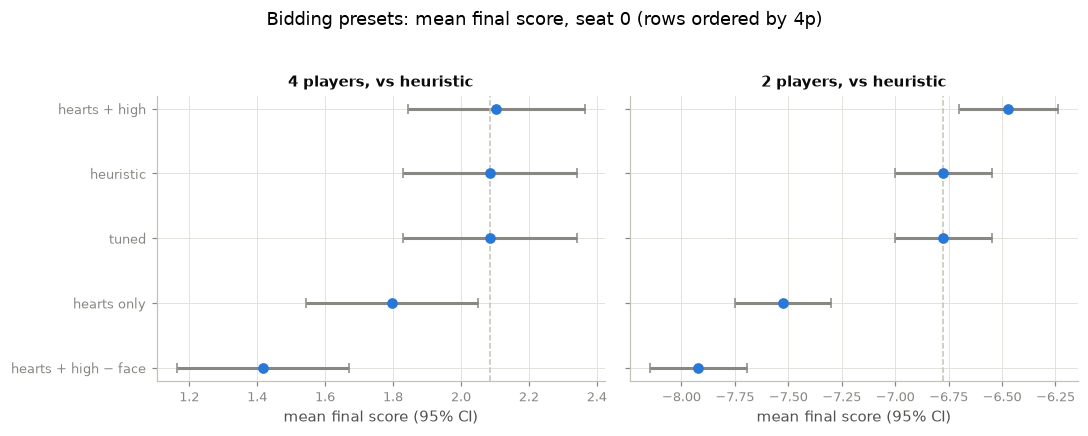

In [2]:
presets = ["fb:hearts_only", "fb:hearts_high", "fb:hearts_high_minus_face", "fb:tuned"]
labels = {"fb:hearts_only": "hearts only", "fb:hearts_high": "hearts + high",
          "fb:hearts_high_minus_face": "hearts + high − face", "fb:tuned": "tuned",
          "heuristic": "heuristic", "random": "random"}

# One fixed row order (by 4p mean) for both panels, so rows line up.
order = sorted(
    presets + ["heuristic"],
    key=lambda c: sweep_h4.loc[sweep_h4["candidate"] == c, "final_score"].mean(),
)
ys = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, (games, title) in zip(axes, [(sweep_h4, "4 players, vs heuristic"),
                                     (sweep_h2, "2 players, vs heuristic")]):
    stats = {c: mean_ci(games.loc[games["candidate"] == c, "final_score"]) for c in order}
    ax.errorbar([stats[c][0] for c in order], ys, xerr=[stats[c][1] for c in order],
                fmt="o", color=viz.BLUE, ecolor=viz.MUTED, capsize=3)
    ax.axvline(stats["heuristic"][0], color=viz.BASELINE, linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("mean final score (95% CI)")
axes[0].set_yticks(ys, [labels[c] for c in order])
fig.suptitle("Bidding presets: mean final score, seat 0 (rows ordered by 4p)", y=1.03)
fig.tight_layout()

**Reading it:** `tuned` sits exactly on `heuristic` (they are the same
bidder, expressed two ways). The user hypotheses land in a tight band:
`hearts + high` is competitive with the tuned weights (slightly ahead at 2
players), plain `hearts only` gives most of the value, and **subtracting
face cards hurts** — an off-suit king is a mild asset (it wins when its
suit is led and no trump appears), not a liability.

tuned mean: 2.09
best grid point: fb:g_h0.4_hh0.45_o0.35 -> paired edge over tuned +0.55 ± 0.30


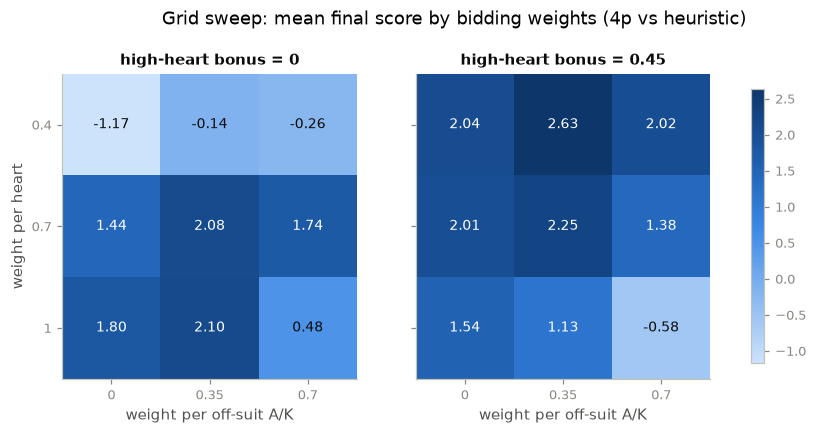

In [3]:
# The 18-point weight grid (4p vs heuristic): where is bidding EV maximized?
grid = sweep_h4[sweep_h4["candidate"].str.startswith("fb:g_")].copy()
parts = grid["candidate"].str.extract(r"g_h(?P<wh>[\d.]+)_hh(?P<whh>[\d.]+)_o(?P<wo>[\d.]+)")
grid[["wh", "whh", "wo"]] = parts.astype(float)
cell_means = grid.groupby(["whh", "wh", "wo"])["final_score"].mean()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=True)
vmin, vmax = cell_means.min(), cell_means.max()
for ax, whh in zip(axes, [0.0, 0.45]):
    mat = cell_means.loc[whh].unstack("wo")
    im = ax.imshow(mat.values, cmap=viz.SEQUENTIAL, vmin=vmin, vmax=vmax, aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.values[i, j]
            ax.annotate(f"{v:.2f}", (j, i), ha="center", va="center", fontsize=9,
                        color="white" if v > (vmin + vmax) / 2 else viz.INK)
    ax.set_xticks(range(mat.shape[1]), [f"{c:g}" for c in mat.columns])
    ax.set_yticks(range(mat.shape[0]), [f"{r:g}" for r in mat.index])
    ax.set_xlabel("weight per off-suit A/K")
    ax.set_title(f"high-heart bonus = {whh:g}", fontsize=10)
    ax.grid(False)
axes[0].set_ylabel("weight per heart")
fig.suptitle("Grid sweep: mean final score by bidding weights (4p vs heuristic)", y=1.04)
fig.colorbar(im, ax=axes, shrink=0.9)

tuned_mean = sweep_h4.loc[sweep_h4["candidate"] == "fb:tuned", "final_score"].mean()
best_label = grid.groupby("candidate")["final_score"].mean().idxmax()
edge = paired_edge(sweep_h4, best_label, "fb:tuned")
m, half = mean_ci(edge)
print(f"tuned mean: {tuned_mean:.2f}")
print(f"best grid point: {best_label} -> paired edge over tuned {m:+.2f} ± {half:.2f}")

**Reading it:** the surface is a ridge, not a peak — many weightings within
~0.5 points of each other. Two robust gradients: (1) the high-heart bonus
(`whh=0.45`) helps at *low* base heart weight and hurts at high weight
(double-counting strong hearts leads to overbidding); (2) a moderate
off-suit A/K weight (~0.35) beats both 0 and 0.7. The best grid point —
low base heart weight, high-heart bonus, moderate off-suit — beats the
tuned weights by a small but statistically real margin (paired CI excludes
zero). The structural story: **underbid rather than overbid** — discount
low hearts steeply and lean on the cards that actually win tricks; a miss
costs the same in either direction, but low bids are easier to hit.

## 2. Play styles and position

Now the mirror experiment: bidding fixed (heuristic), play varied. Styles:
`hearts_first` (shed trump high-first), `high_first`, `low_first`,
`adaptive` (the want-trick-conditioned baseline), plus phase-switching
combos at both timescales — `phased_round` switches style across the
1→7→1 game, `phased_trick` switches within each round's tricks.

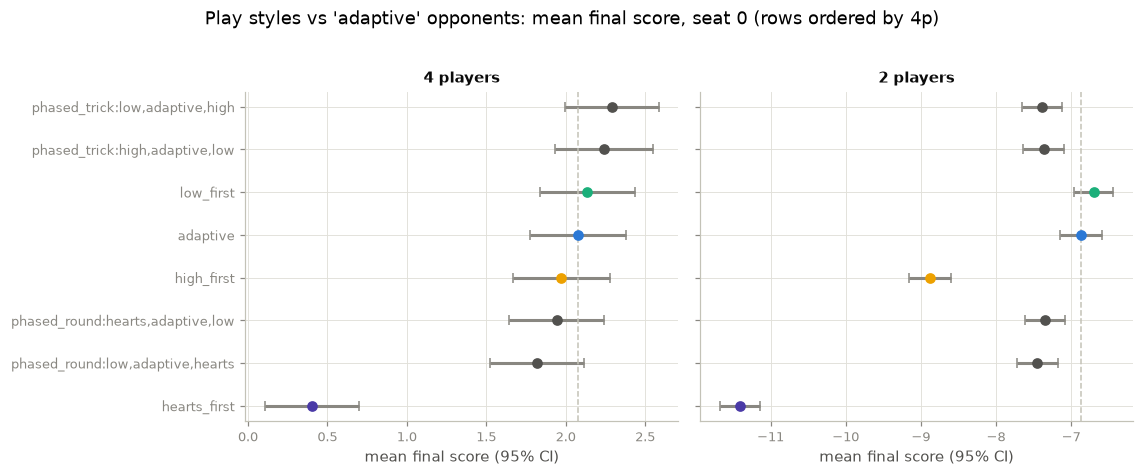

In [4]:
import json

STYLE_COLOR = {"adaptive": viz.BLUE, "low_first": viz.AQUA,
               "high_first": viz.YELLOW, "hearts_first": viz.VIOLET}


def load_styles(players):
    frames = {}
    root = DATA / f"play_styles/{players}p"
    for d in sorted(root.iterdir()):
        if d.is_dir():
            label = json.loads((d / "manifest.json").read_text())["args"]["candidate"]
            frames[label] = {
                "games": pd.read_parquet(d / "games.parquet"),
                "rounds": pd.read_parquet(d / "rounds.parquet"),
                "plays": pd.read_parquet(d / "plays.parquet"),
            }
    return frames


styles4 = load_styles(4)
styles2 = load_styles(2)

# One fixed row order (by 4p mean) for both panels, so rows line up.
def seat0_scores(frames, label):
    return frames[label]["games"].query("seat == 0")["final_score"]


style_order = sorted(styles4, key=lambda label: seat0_scores(styles4, label).mean())
ys = np.arange(len(style_order))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for ax, (frames, title) in zip(axes, [(styles4, "4 players"), (styles2, "2 players")]):
    for y, label in zip(ys, style_order):
        m, half = mean_ci(seat0_scores(frames, label))
        ax.errorbar([m], [y], xerr=[half], fmt="o",
                    color=STYLE_COLOR.get(label, viz.INK_2),
                    ecolor=viz.MUTED, capsize=3)
    ax.axvline(seat0_scores(frames, "adaptive").mean(),
               color=viz.BASELINE, linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("mean final score (95% CI)")
axes[0].set_yticks(ys, style_order)
fig.suptitle("Play styles vs 'adaptive' opponents: mean final score, seat 0 "
             "(rows ordered by 4p)", y=1.02)
fig.tight_layout()

**Reading it:** the spread across play styles is *much* smaller than across
bidding strategies — play matters, but bidding matters more. Consistent
findings across both table sizes: **`hearts_first` is clearly the worst**
(burning trump early throws away the cards that control tricks), and
**`low_first` is a surprisingly strong fixed rule**, at or above the
adaptive baseline. That makes sense given the scoring: most bids are low,
so a style that avoids winning extra tricks hits its bid more often. The
phased combos land between their components — no timescale switch beats
just playing the better component all the time by a significant margin.

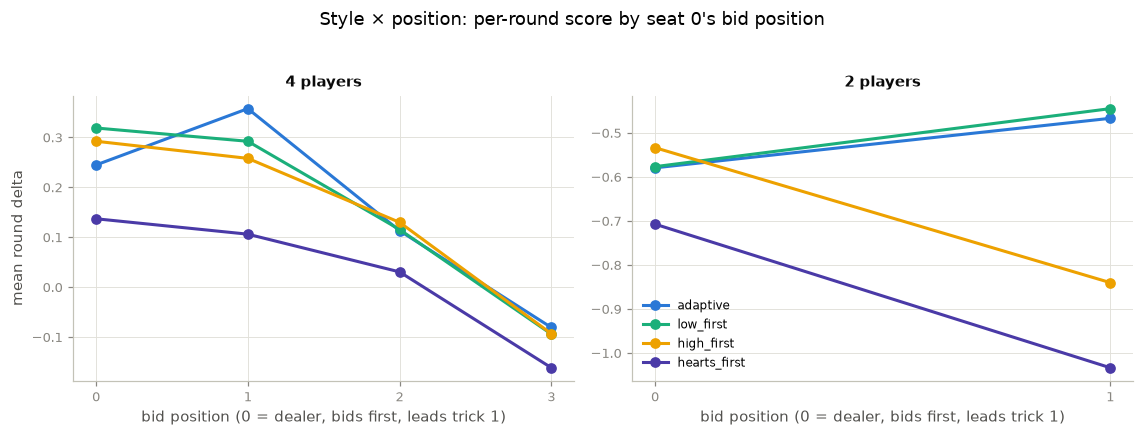

In [5]:
# Does the best style depend on position? Round-level delta by bid position.
pure = ["adaptive", "low_first", "high_first", "hearts_first"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for ax, (frames, players, title) in zip(
        axes, [(styles4, 4, "4 players"), (styles2, 2, "2 players")]):
    for label in pure:
        r = frames[label]["rounds"].query("seat == 0")
        by_pos = r.groupby("bid_position")["delta"].mean()
        ax.plot(by_pos.index, by_pos.values, "o-", color=STYLE_COLOR[label], label=label)
    ax.set_xticks(range(players))
    ax.set_xlabel("bid position (0 = dealer, bids first, leads trick 1)")
    ax.set_title(title, fontsize=10)
axes[0].set_ylabel("mean round delta")
axes[1].legend(fontsize=8, loc="lower left")
fig.suptitle("Style × position: per-round score by seat 0's bid position", y=1.03)
fig.tight_layout()

**Reading it:** at 4 players, position moves scores more than style does —
the three sane styles track the same positional profile (peaking early,
sagging into the last-bidder seat), so your seat doesn't change which rule
to use. At 2 players there *is* a real interaction: **`high_first` is
competitive when dealing and clearly worse when not** — as the dealer you
lead, and a led high card always contends (notebook 04's structural edge);
as the follower the same aggression just burns winners into your
opponent's leads. Aggressive play belongs to the seat that leads.

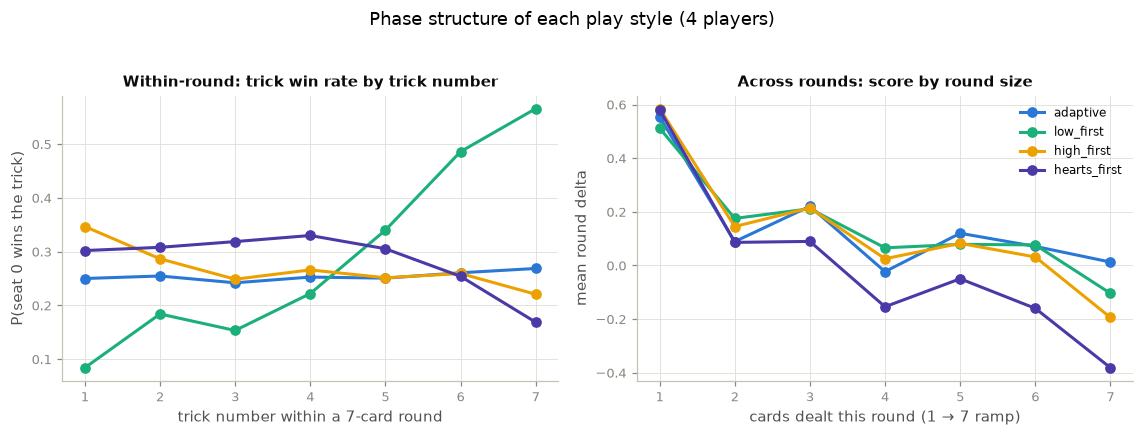

In [6]:
# Within-round phase: when does each style win its tricks? (7-card rounds, 4p)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for label in pure:
    plays = styles4[label]["plays"]
    p7 = plays[(plays["round_index"] == 7) & (plays["seat"] == 0)]
    win = p7.assign(won=p7["trick_winner"] == 0).groupby("trick_index")["won"].mean()
    axes[0].plot(win.index + 1, win.values, "o-", color=STYLE_COLOR[label], label=label)

    rounds = styles4[label]["rounds"].query("seat == 0")
    by_cards = rounds.groupby("cards_dealt")["delta"].mean()
    axes[1].plot(by_cards.index, by_cards.values, "o-", color=STYLE_COLOR[label], label=label)

axes[0].set_xlabel("trick number within a 7-card round")
axes[0].set_ylabel("P(seat 0 wins the trick)")
axes[0].set_title("Within-round: trick win rate by trick number", fontsize=10)
axes[1].set_xlabel("cards dealt this round (1 → 7 ramp)")
axes[1].set_ylabel("mean round delta")
axes[1].set_title("Across rounds: score by round size", fontsize=10)
axes[1].legend(fontsize=8)
fig.suptitle("Phase structure of each play style (4 players)", y=1.03)
fig.tight_layout()

**Reading it (both timescales):** *within a round*, the styles have very
different signatures — `high_first` front-loads its trick wins and runs
dry by the late tricks, `low_first` is the mirror image, and `adaptive`
stays flat because it chases tricks only while under bid. But the *score*
by round size (right) shows those signatures wash out except at the
extremes: fixed aggressive styles bleed the most in the big 5–7-card
rounds, where winning unwanted tricks is easiest. This is the phase
finding: **strategy differences are amplified by round size (the game-level
ramp), not by trick position (the within-round clock)** — consistent with
the phased-trick combos above buying at most a marginal gain.

## 3. The first-dealer edge (2 players)

Both seats run the *same* policy; the first dealer is fixed at seat 0.
Whatever score gap remains is pure structure: the first dealer deals (and
leads) rounds 1, 3, 5, … — including round 7, the 7-card round — while
seat 1 deals the even rounds.

heuristic: first-dealer edge +0.303 ± 0.150 over 20000 games
random: first-dealer edge +0.170 ± 0.170 over 20000 games


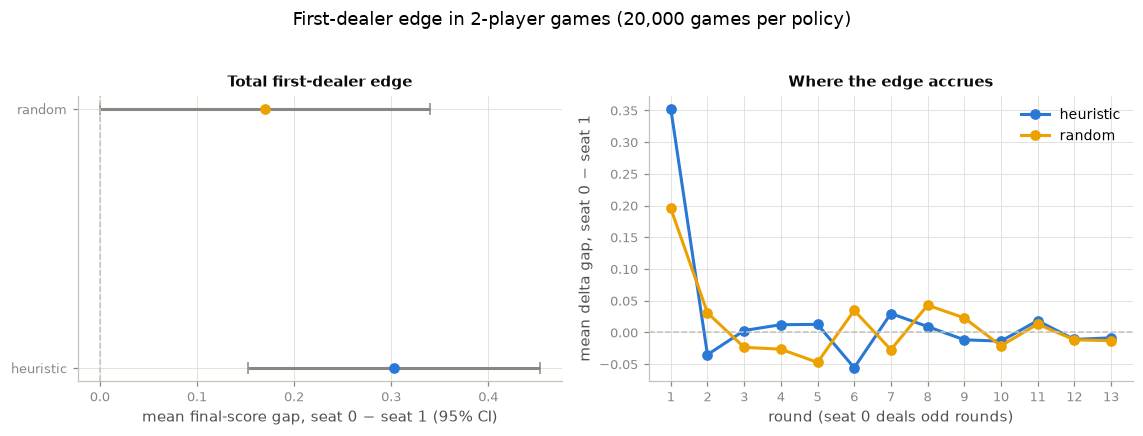

In [7]:
POLICY_COLOR = {"heuristic": viz.BLUE, "random": viz.YELLOW}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))

for policy, color in POLICY_COLOR.items():
    g = pd.read_parquet(DATA / f"dealer_edge/{policy}/games.parquet")
    per_game = g.pivot(index="game_seed", columns="seat", values="final_score")
    diff = per_game[0] - per_game[1]
    m, half = mean_ci(diff)
    axes[0].errorbar([m], [policy], xerr=[half], fmt="o", color=color,
                     ecolor=viz.MUTED, capsize=4)
    print(f"{policy}: first-dealer edge {m:+.3f} ± {half:.3f} over {len(diff)} games")

    r = pd.read_parquet(DATA / f"dealer_edge/{policy}/rounds.parquet")
    per_round = r.pivot_table(index="round_index", columns="seat", values="delta")
    axes[1].plot(per_round.index, per_round[0] - per_round[1], "o-",
                 color=color, label=policy)

axes[0].axvline(0, color=viz.BASELINE, linestyle="--", linewidth=1)
axes[0].set_xlabel("mean final-score gap, seat 0 − seat 1 (95% CI)")
axes[0].set_title("Total first-dealer edge", fontsize=10)
axes[1].axhline(0, color=viz.BASELINE, linestyle="--", linewidth=1)
axes[1].set_xticks(range(1, 14))
axes[1].set_xlabel("round (seat 0 deals odd rounds)")
axes[1].set_ylabel("mean delta gap, seat 0 − seat 1")
axes[1].set_title("Where the edge accrues", fontsize=10)
axes[1].legend(fontsize=9)
fig.suptitle("First-dealer edge in 2-player games (20,000 games per policy)", y=1.03)
fig.tight_layout()

**Reading it:** being first dealer is worth a small but real edge for the
heuristic (+0.30, CI excluding zero; the random control is about half that
and borderline). The decomposition is the surprise: **essentially the
whole edge is earned in round 1** — the 1-card round dealt from the fresh
uniform shuffle, where the dealer leads the round's only trick and a led
card always contends (notebook 04's structural result at its purest).
From round 2 onward the per-round dealer effect nets out to ≈0, even in
the later 1-card rounds — those are dealt from the play-ordered recycled
deck, whose correlations evidently wash the leader's advantage out. So
"first dealer" in a 2-player game really means "leader of the one clean
coin-flip round."

## 4. Dominance: everything vs random

The user's question — "how much better than random play are these
strategies?" — answered with paired seeds: each candidate's per-game score
minus `random`'s score in the *same* games (same decks, same opponents).

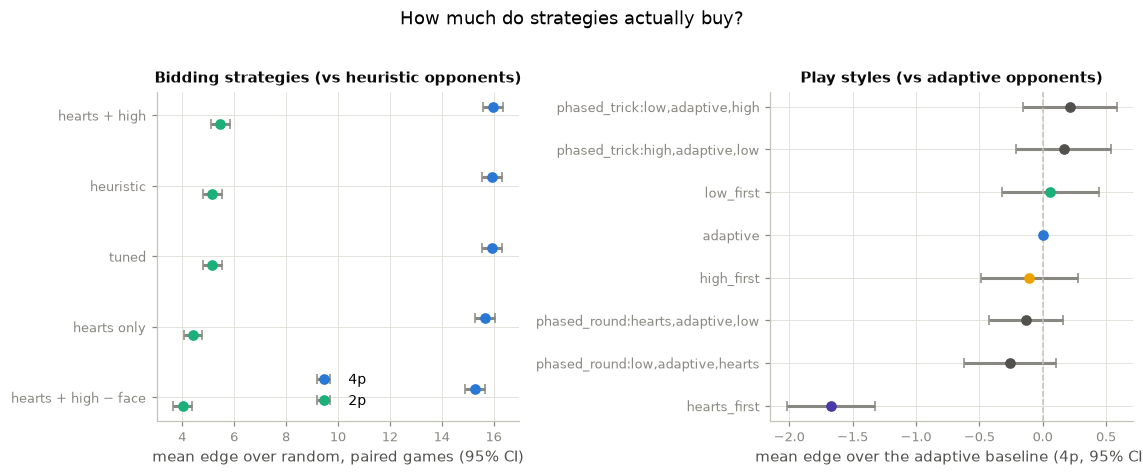

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

rows = []
for cand in presets + ["heuristic"]:
    for games, env in [(sweep_h4, "4p"), (sweep_h2, "2p")]:
        edge = paired_edge(games, cand, "random")
        m, half = mean_ci(edge)
        rows.append({"candidate": labels[cand], "env": env, "edge": m, "half": half})
dom = pd.DataFrame(rows)
order = dom.query("env == '4p'").sort_values("edge")["candidate"]
ys = np.arange(len(order))
for env, color, dy in [("4p", viz.BLUE, 0.12), ("2p", viz.AQUA, -0.12)]:
    sub = dom[dom["env"] == env].set_index("candidate").loc[order]
    axes[0].errorbar(sub["edge"], ys + dy, xerr=sub["half"], fmt="o",
                     color=color, ecolor=viz.MUTED, capsize=3, label=env)
axes[0].set_yticks(ys, order)
axes[0].set_xlabel("mean edge over random, paired games (95% CI)")
axes[0].set_title("Bidding strategies (vs heuristic opponents)", fontsize=10)
axes[0].legend(fontsize=9)

rows = []
for label_, f in styles4.items():
    a = f["games"].query("seat == 0")[["game_seed", "final_score"]]
    b = styles4["adaptive"]["games"].query("seat == 0")[["game_seed", "final_score"]]
    d = a.merge(b, on="game_seed", suffixes=("_a", "_b"))
    m, half = mean_ci(d["final_score_a"] - d["final_score_b"])
    rows.append({"candidate": label_, "edge": m, "half": half})
sty = pd.DataFrame(rows).sort_values("edge")
ys = np.arange(len(sty))
colors = [STYLE_COLOR.get(c, viz.INK_2) for c in sty["candidate"]]
for y, (m, half, color) in enumerate(zip(sty["edge"], sty["half"], colors)):
    axes[1].errorbar([m], [y], xerr=[half], fmt="o", color=color,
                     ecolor=viz.MUTED, capsize=3)
axes[1].set_yticks(ys, sty["candidate"])
axes[1].axvline(0, color=viz.BASELINE, linestyle="--", linewidth=1)
axes[1].set_xlabel("mean edge over the adaptive baseline (4p, 95% CI)")
axes[1].set_title("Play styles (vs adaptive opponents)", fontsize=10)
fig.suptitle("How much do strategies actually buy?", y=1.02)
fig.tight_layout()

## Takeaways

1. **Bidding is where the points are.** Any sane feature bidder beats
   random by ~16 points/game at 4p; the differences *between* sensible
   feature weightings are ~1 point. Bid your hearts (weighted below 1 —
   underbidding is the cheaper miss), add ~0.35 per off-suit A/K, and don't
   penalize face cards.
2. **Play styles move ~1–2 points, and the fixed rules bracket the
   adaptive baseline.** `low_first` is a strong default (low bids are the
   norm, and it avoids accidental tricks); `hearts_first` is the one
   clearly bad idea — trump is trick *control*, don't shed it.
3. **Position mostly changes your score, not your best strategy** — style
   orderings are stable across bid positions at 4 players; the one real
   interaction is heads-up, where aggressive high-card play only works
   from the leader's (dealer's) seat.
4. **First dealer in a 2-player game is a real, small structural edge
   (+0.30 for the heuristic over 20k games) — and it is earned almost
   entirely in round 1**, the only round dealt from a fresh shuffle, where
   the dealer leads the game's one clean single-trick coin flip.
5. **Phases:** strategy differences scale with *round size* (the game-level
   1→7→1 ramp), while within-round trick-phase switching buys little beyond
   its better component.